# Power System Load Type Prediction
**Assignment 2 | Multiclass classification | Chronological holdout**

## Objective
Predict `Load_Type` (`Light_Load`, `Medium_Load`, or `Maximum_Load`) from historical power-system measurements. The final calendar month in the dataset is held out as the test set, as required by the assignment.

## Workflow
1. Load and inspect the raw data.
2. Parse timestamps, inspect data quality, and remove exact duplicate timestamps.
3. Perform exploratory data analysis (EDA).
4. Engineer calendar and cyclical time features.
5. Split chronologically: all data before December 2018 for training; December 2018 for testing.
6. Fit preprocessing and classification pipelines on training data only.
7. Compare Logistic Regression and Random Forest using accuracy, precision, recall, F1-score, and a confusion matrix.
8. Summarize results and limitations.

**Leakage safeguards:** The target is never used as a feature; the test month is not used to fit imputers, scalers, or models; the split is chronological rather than random.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, confusion_matrix
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Works when run from the project root or from the notebooks/ directory.
candidate_paths = [
    Path("data/raw/load_data.csv"),
    Path("../data/raw/load_data.csv"),
    Path("/mnt/data/power_load_prediction/data/raw/load_data.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find data/raw/load_data.csv. Run from the project root or notebooks/ folder.")

print(f"Dataset path: {DATA_PATH.resolve()}")

Matplotlib is building the font cache; this may take a moment.


Dataset path: /Users/prasad/Downloads/power_load_prediction/data/raw/load_data.csv


## 2. Load data and inspect structure

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date_Time,35041,35040,31-12-2018 20:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Usage_kWh,33482.0,NaN,NaN,NaN,30.873061,41.415015,0.0,3.31,5.29,53.56,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,NaN,NaN,NaN,14.704573,20.342721,0.0,2.34,5.18,23.51,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,NaN,NaN,NaN,4.386097,9.090181,0.0,0.0,0.0,2.298558,78.809
CO2(tCO2),34586.0,NaN,NaN,NaN,0.012947,0.019726,0.0,0.0,0.0,0.02,0.188166
Lagging_Current_Power_Factor,34691.0,NaN,NaN,NaN,90.740871,39.745395,0.0,66.295,90.08,100.0,299.996814
Leading_Current_Power_Factor,33570.0,NaN,NaN,NaN,94.926552,49.826872,0.0,99.8,100.0,100.0,299.969494
NSM,34586.0,NaN,NaN,NaN,48013.664032,34046.492333,0.0,22500.0,45000.0,68400.0,248821.810465
Load_Type,35041,3,Light_Load,18073,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data quality checks

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nMissing values by column:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_count").assign(
    missing_percent=(missing / len(df) * 100).round(2)
))

print("\\nTarget class counts:")
display(df["Load_Type"].value_counts().to_frame("count"))
display((df["Load_Type"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

# Parse timestamp using the format present in the supplied CSV.
df["Date_Time"] = pd.to_datetime(df["Date_Time"], format="%d-%m-%Y %H:%M", errors="coerce")
print("Unparseable timestamps:", int(df["Date_Time"].isna().sum()))
print("Timestamp range:", df["Date_Time"].min(), "to", df["Date_Time"].max())
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate timestamps:", int(df.duplicated(subset=["Date_Time"]).sum()))

Column names:
['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']
\nMissing values by column:


,missing_count,missing_percent
Usage_kWh,1559,4.45
Leading_Current_Power_Factor,1471,4.20
Leading_Current_Reactive_Power_kVarh,1156,3.30
Lagging_Current_Reactive.Power_kVarh,876,2.50
CO2(tCO2),455,1.30
NSM,455,1.30
Lagging_Current_Power_Factor,350,1.00
Date_Time,0,0.00
Load_Type,0,0.00


\nTarget class counts:


,count
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


,percent
Load_Type,
Light_Load,51.58
Medium_Load,27.67
Maximum_Load,20.75


Unparseable timestamps: 0
Timestamp range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00
Exact duplicate rows: 0
Duplicate timestamps: 1


## 4. Clean timestamps and duplicates

In [4]:
# Rows without a valid timestamp cannot be assigned to a chronological split.
df = df.dropna(subset=["Date_Time"]).copy()

# Keep the first row when a timestamp is duplicated. Report the number removed.
duplicate_timestamps = int(df.duplicated(subset=["Date_Time"]).sum())
df = df.sort_values("Date_Time").drop_duplicates(subset=["Date_Time"], keep="first").reset_index(drop=True)

print("Duplicate timestamps removed:", duplicate_timestamps)
print("Shape after timestamp cleaning:", df.shape)
print("Missing numeric values are retained here and imputed inside each training pipeline.")

Duplicate timestamps removed: 1
Shape after timestamp cleaning: (35040, 9)
Missing numeric values are retained here and imputed inside each training pipeline.


## 5. Exploratory data analysis

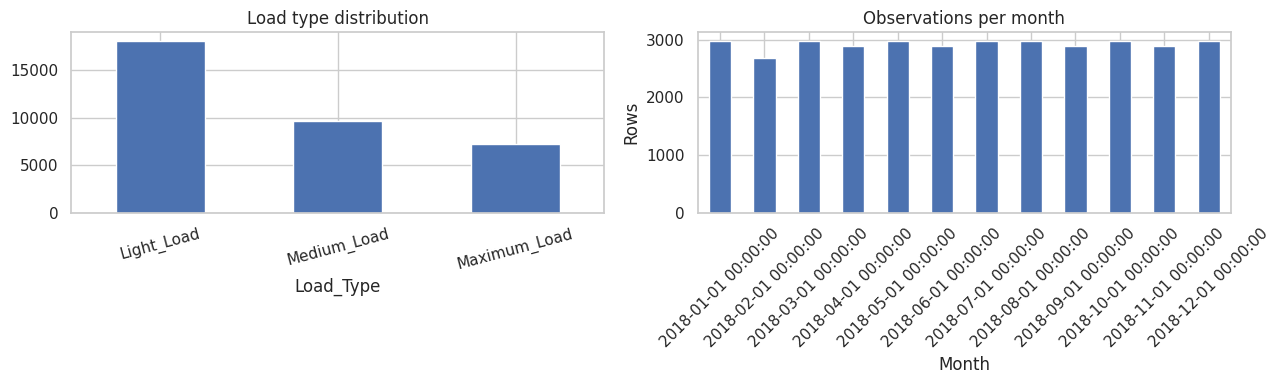

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ["Light_Load", "Medium_Load", "Maximum_Load"]
df["Load_Type"].value_counts().reindex(order).plot(kind="bar", ax=axes[0])
axes[0].set_title("Load type distribution")
axes[0].tick_params(axis="x", rotation=15)

monthly_counts = df.set_index("Date_Time").resample("MS")["Load_Type"].count()
monthly_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Observations per month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Rows")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
Usage_kWh,1.00,0.74,-0.27,0.83,0.19,0.22,0.18
Lagging_Current_Reactive.Power_kVarh,0.74,1.00,-0.34,0.74,0.06,0.26,0.07
Leading_Current_Reactive_Power_kVarh,-0.27,-0.34,1.00,-0.28,0.26,-0.60,0.28
CO2(tCO2),0.83,0.74,-0.28,1.00,0.18,0.23,0.18
Lagging_Current_Power_Factor,0.19,0.06,0.26,0.18,1.00,-0.19,0.25
Leading_Current_Power_Factor,0.22,0.26,-0.60,0.23,-0.19,1.00,-0.20
NSM,0.18,0.07,0.28,0.18,0.25,-0.20,1.00


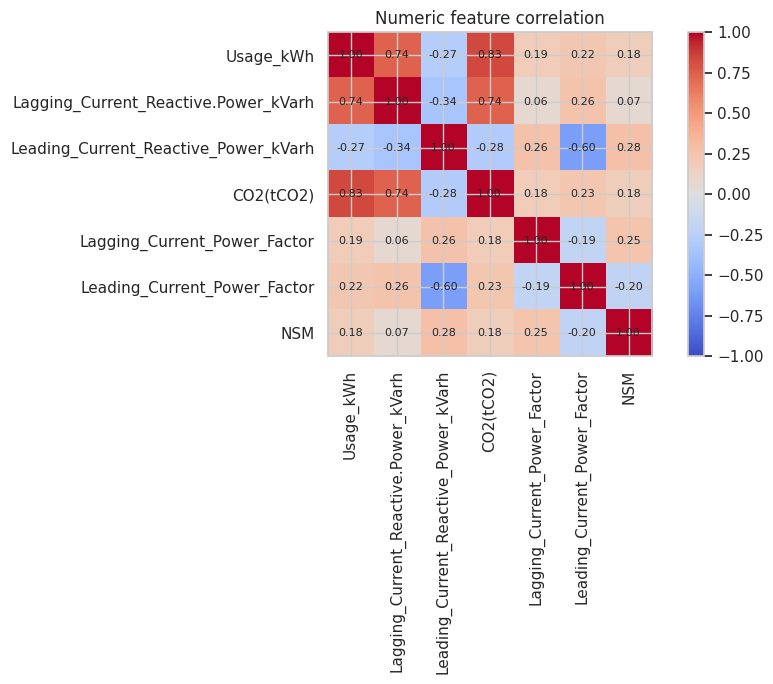

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].corr().round(2))

plt.figure(figsize=(10, 7))
corr = df[numeric_cols].corr()
image = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Numeric feature correlation")
plt.tight_layout()
plt.show()

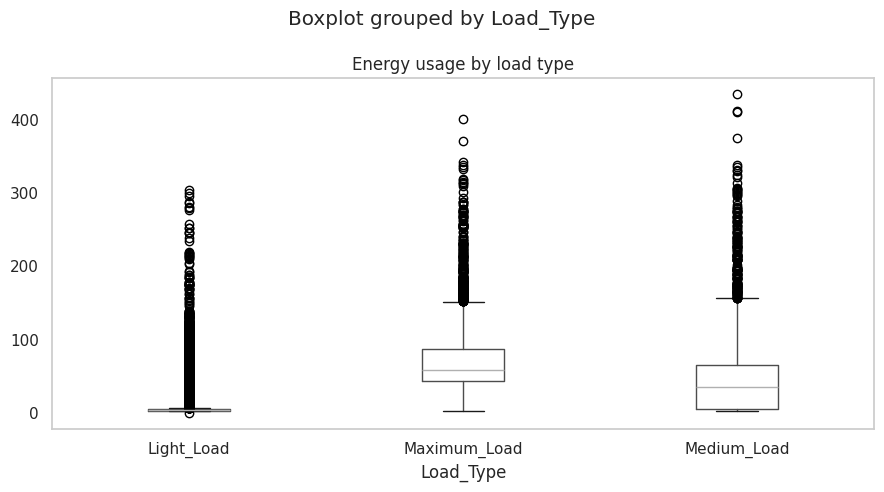

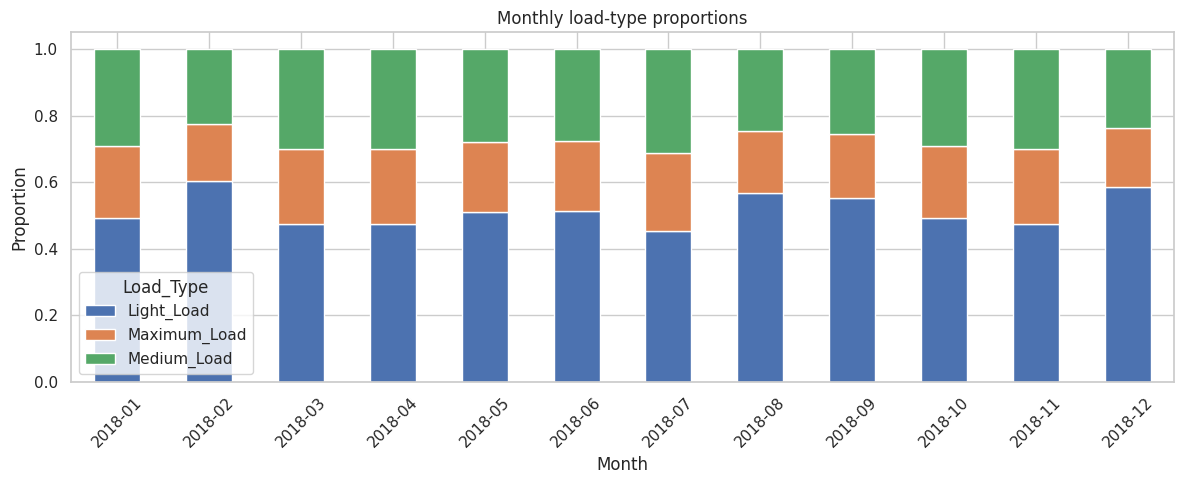

In [7]:
# Explore energy usage by class; boxplots show spread and potential outliers.
plt.figure(figsize=(9, 5))
df.boxplot(column="Usage_kWh", by="Load_Type", ax=plt.gca(), grid=False)
plt.title("Energy usage by load type")
plt.tight_layout()
plt.show()

# Class composition over time can reveal changes in the target distribution.
monthly_class = pd.crosstab(df["Date_Time"].dt.to_period("M").astype(str), df["Load_Type"], normalize="index")
monthly_class.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Monthly load-type proportions")
plt.xlabel("Month")
plt.ylabel("Proportion")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Feature engineering and chronological split

In [8]:
# Calendar/time features are derived from the timestamp. Cyclical encodings represent
# the fact that hour 23 is close to hour 0, and December is close to January.
def add_time_features(frame):
    out = frame.copy()
    dt = out["Date_Time"]
    out["year"] = dt.dt.year
    out["month"] = dt.dt.month
    out["day"] = dt.dt.day
    out["day_of_week"] = dt.dt.dayofweek
    out["hour"] = dt.dt.hour
    out["minute"] = dt.dt.minute
    out["day_of_year"] = dt.dt.dayofyear
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    out["month_sin"] = np.sin(2 * np.pi * out["month"] / 12)
    out["month_cos"] = np.cos(2 * np.pi * out["month"] / 12)
    return out

df_model = add_time_features(df)

# Determine the last calendar month from the dataset rather than hard-coding a year.
last_month = df_model["Date_Time"].dt.to_period("M").max()
test_mask = df_model["Date_Time"].dt.to_period("M") == last_month
train_df = df_model.loc[~test_mask].copy()
test_df = df_model.loc[test_mask].copy()

print("Held-out test month:", str(last_month))
print("Training period:", train_df["Date_Time"].min(), "to", train_df["Date_Time"].max())
print("Test period:", test_df["Date_Time"].min(), "to", test_df["Date_Time"].max())
print(f"Training rows: {len(train_df):,} ({len(train_df)/len(df_model):.1%})")
print(f"Test rows: {len(test_df):,} ({len(test_df)/len(df_model):.1%})")

target = "Load_Type"
drop_cols = ["Date_Time", target]
feature_cols = [c for c in df_model.columns if c not in drop_cols]
X_train, y_train = train_df[feature_cols], train_df[target]
X_test, y_test = test_df[feature_cols], test_df[target]

print("Features used:", feature_cols)
print("Missing training feature values:", int(X_train.isna().sum().sum()))

Held-out test month: 2018-12
Training period: 2018-01-01 00:00:00 to 2018-11-30 23:45:00
Test period: 2018-12-01 00:00:00 to 2018-12-31 23:45:00
Training rows: 32,064 (91.5%)
Test rows: 2,976 (8.5%)
Features used: ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'year', 'month', 'day', 'day_of_week', 'hour', 'minute', 'day_of_year', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
Missing training feature values: 5744


## 7. Train and compare classification models

In [9]:
# All numeric features are imputed using training-set medians. Scaling is included
# for Logistic Regression; Random Forest does not require feature scaling.
numeric_features = feature_cols

log_reg = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
])

random_forest = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

models = {
    "Logistic Regression": log_reg,
    "Random Forest": random_forest,
}

results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = y_pred
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(results_df.style.format({c: "{:.4f}" for c in results_df.columns if c != "model"}))

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Random Forest,0.9519,0.9368,0.9578,0.9467,0.9521
1,Logistic Regression,0.5746,0.5295,0.5049,0.5002,0.6163


## 8. Evaluate the selected model

Best model by macro F1: Random Forest
\nClassification report:
              precision    recall  f1-score   support

  Light_Load       0.98      0.94      0.96      1744
 Medium_Load       0.92      0.98      0.95       704
Maximum_Load       0.91      0.95      0.93       528

    accuracy                           0.95      2976
   macro avg       0.94      0.96      0.95      2976
weighted avg       0.95      0.95      0.95      2976



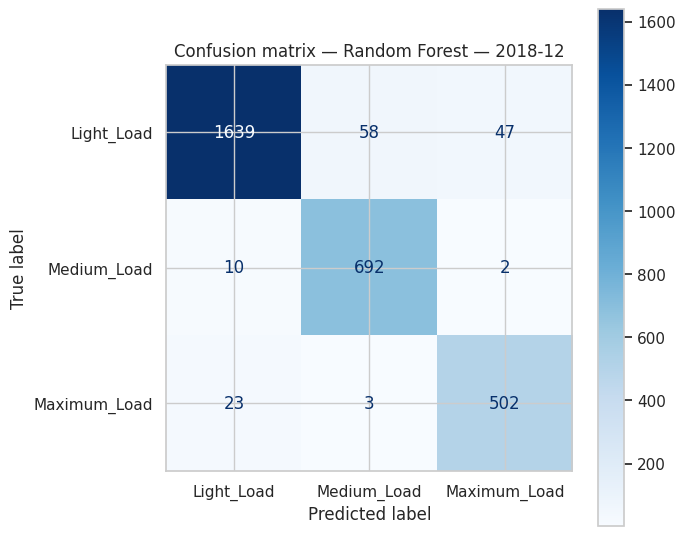

In [10]:
best_name = results_df.loc[0, "model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print("Best model by macro F1:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, best_pred, labels=order, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, labels=order, display_labels=order,
    cmap="Blues", values_format="d", ax=ax
)
ax.set_title(f"Confusion matrix — {best_name} — {last_month}")
plt.tight_layout()
plt.show()

## 9. Random Forest feature importance (if applicable)

,importance
NSM,0.202364
hour,0.181564
hour_sin,0.090165
Usage_kWh,0.079780
hour_cos,0.075789
CO2(tCO2),0.059067
day_of_year,0.049762
month_cos,0.048251
Lagging_Current_Power_Factor,0.040272
month,0.034765


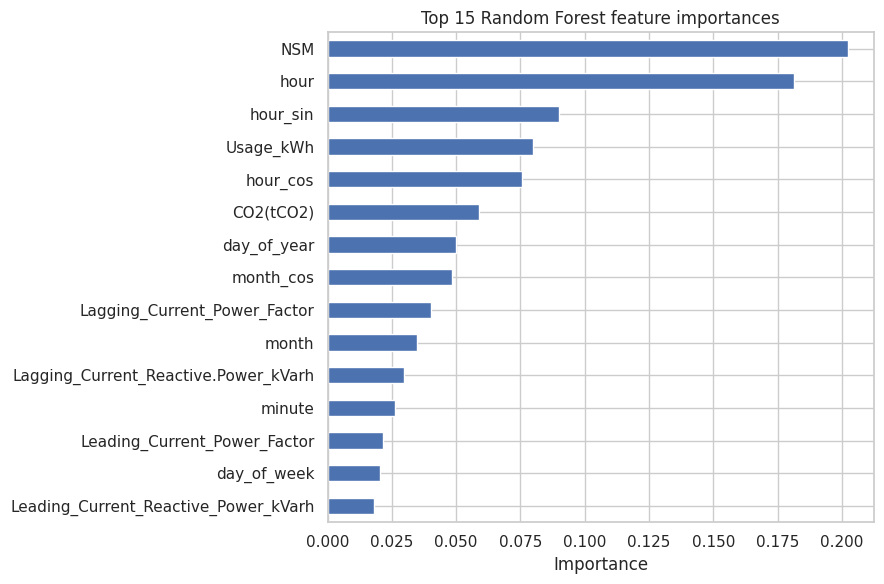

In [11]:
if best_name == "Random Forest":
    rf = best_model.named_steps["model"]
    importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
    display(importance.to_frame("importance"))
    importance.sort_values().plot(kind="barh", figsize=(9, 6))
    plt.title("Top 15 Random Forest feature importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Logistic Regression selected. For coefficient-based interpretation, inspect the fitted coefficients after scaling.")

## 10. Conclusions and limitations

In [12]:
print(f"Test month: {last_month}")
print(f"Best model by macro F1: {best_name}")
best_row = results_df.iloc[0]
print(f"Accuracy: {best_row['accuracy']:.4f}")
print(f"Macro precision: {best_row['precision_macro']:.4f}")
print(f"Macro recall: {best_row['recall_macro']:.4f}")
print(f"Macro F1: {best_row['f1_macro']:.4f}")
print(f"Weighted F1: {best_row['f1_weighted']:.4f}")

Test month: 2018-12
Best model by macro F1: Random Forest
Accuracy: 0.9519
Macro precision: 0.9368
Macro recall: 0.9578
Macro F1: 0.9467
Weighted F1: 0.9521


### Interpretation notes
- December is used only for final testing; the model and preprocessing are fitted on January–November data.
- Macro-averaged metrics weight all three classes equally, while weighted F1 accounts for class frequency.
- This is a single chronological holdout, so results may depend on the selected month. A stronger follow-up would use expanding-window time-series validation on the training period for model tuning.
- `Load_Type` is the label and is excluded from the input features. If the dataset's load labels were originally derived directly from some measured columns, that domain relationship may make classification easier; verify the label-generation method before production use.
- Feature importance indicates model association, not causality.